In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv(
    "지역별 일 최고기온 및 최저기온.csv",
    encoding="cp949"
)

In [3]:
# 데이터 상위 5개 행
display(df.head())

# 데이터 크기
print(df.shape)

# 컬럼 및 데이터 타입
df.info()

,지점,지점명,일시,최저기온(°C),최고기온(°C)
0,90,속초,2021-01-01,-7.7,1.2
1,90,속초,2021-01-02,-6.3,1.5
2,90,속초,2021-01-03,-5.8,0.7
3,90,속초,2021-01-04,-4.2,3.2
4,90,속초,2021-01-05,-7.3,0.1


(175402, 5)
<class 'pandas.DataFrame'>
RangeIndex: 175402 entries, 0 to 175401
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype  
---  ------    --------------   -----  
 0   지점        175402 non-null  int64  
 1   지점명       175402 non-null  str    
 2   일시        175402 non-null  str    
 3   최저기온(°C)  175392 non-null  float64
 4   최고기온(°C)  175394 non-null  float64
dtypes: float64(2), int64(1), str(2)
memory usage: 6.7 MB


In [4]:
# 관측소 개수
print("관측소 개수:", df["지점"].nunique())

# 관측소별 이름 확인
print(df[["지점", "지점명"]].drop_duplicates().sort_values("지점"))

# 날짜 범위 확인
print("시작 날짜:", df["일시"].min())
print("종료 날짜:", df["일시"].max())

# 관측소별 데이터 개수
print(df.groupby("지점명").size())

관측소 개수: 97
         지점  지점명
0        90   속초
1826     93  북춘천
3652     95   철원
5478     98  동두천
7304     99   파주
...     ...  ...
167019  288   밀양
168843  289   산청
170667  294   거제
172493  295   남해
174318  296  북부산

[97 rows x 2 columns]
시작 날짜: 2021-01-01
종료 날짜: 2025-12-31
지점명
강릉     1826
강진군    1825
강화     1824
거제     1826
거창     1822
       ... 
합천     1826
해남     1819
홍성     1826
홍천     1822
흑산도    1826
Length: 97, dtype: int64


In [5]:
# 컬럼별 결측치 개수
print(df.isnull().sum())

# 결측치가 있는 행 확인
missing_data = df[df.isnull().any(axis=1)]

display(missing_data)

# 결측치가 있는 관측소별 개수
print(
    missing_data.groupby("지점명").size()
)

지점           0
지점명          0
일시           0
최저기온(°C)    10
최고기온(°C)     8
dtype: int64


,지점,지점명,일시,최저기온(°C),최고기온(°C)
12565,101,춘천,2025-06-05,10.3,NaN
20661,108,서울,2022-08-08,NaN,28.4
50437,143,대구,2024-02-21,3.6,NaN
56239,155,창원,2025-01-10,-10.9,NaN
56240,155,창원,2025-01-11,NaN,4.5
59294,159,부산,2023-05-24,NaN,22.9
61451,162,통영,2024-04-21,NaN,16.6
69405,172,고창,2021-02-04,-4.3,NaN
86505,201,강화,2025-05-07,6.6,NaN
109278,239,세종,2022-09-29,15.1,NaN


지점명
강화     1
경주시    2
고창     1
구미     1
대구     1
부산     1
북창원    1
서울     1
세종     1
영광군    1
의령군    1
진도군    1
창원     2
춘천     1
통영     1
함양군    1
dtype: int64


In [6]:
df["일시"] = pd.to_datetime(df["일시"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 175402 entries, 0 to 175401
Data columns (total 5 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   지점        175402 non-null  int64         
 1   지점명       175402 non-null  str           
 2   일시        175402 non-null  datetime64[us]
 3   최저기온(°C)  175392 non-null  float64       
 4   최고기온(°C)  175394 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(1)
memory usage: 6.7 MB


In [7]:
# 전체 중복 행 확인
print("전체 중복 행:", df.duplicated().sum())

# 관측소와 날짜 기준 중복 확인
print(
    "관측소·날짜 중복:",
    df.duplicated(subset=["지점", "일시"]).sum()
)

전체 중복 행: 0
관측소·날짜 중복: 0


In [8]:
station_count = (
    df.groupby(["지점", "지점명"])
    .agg(
        데이터_개수=("일시", "count"),
        시작일=("일시", "min"),
        종료일=("일시", "max")
    )
    .reset_index()
)

station_count["누락_일수"] = 1826 - station_count["데이터_개수"]

display(
    station_count.sort_values("누락_일수", ascending=False)
)

,지점,지점명,데이터_개수,시작일,종료일,누락_일수
41,181,서청주,976,2023-05-01,2025-12-31,850
96,296,북부산,1084,2023-01-11,2025-12-31,742
38,172,고창,1795,2021-01-01,2025-12-31,31
80,268,진도군,1815,2021-01-01,2025-12-31,11
77,263,의령군,1817,2021-01-01,2025-12-31,9
...,...,...,...,...,...,...
84,276,청송군,1826,2021-01-01,2025-12-31,0
82,272,영주,1826,2021-01-01,2025-12-31,0
86,278,의성,1826,2021-01-01,2025-12-31,0
91,285,합천,1826,2021-01-01,2025-12-31,0


In [9]:
# 전체 분석 기간의 날짜 생성
all_dates = pd.date_range(
    start="2021-01-01",
    end="2025-12-31",
    freq="D"
)

# 관측소별 누락 날짜 확인
missing_dates = {}

for station, group in df.groupby("지점명"):
    observed_dates = pd.DatetimeIndex(group["일시"])
    missing = all_dates.difference(observed_dates)

    if len(missing) > 0:
        missing_dates[station] = missing

# 누락 날짜 출력
for station, dates in missing_dates.items():
    print(f"\n[{station}] 누락 날짜: {len(dates)}개")
    print(dates.tolist())


[강진군] 누락 날짜: 1개
[Timestamp('2025-03-16 00:00:00')]

[강화] 누락 날짜: 2개
[Timestamp('2022-10-31 00:00:00'), Timestamp('2022-11-01 00:00:00')]

[거창] 누락 날짜: 4개
[Timestamp('2021-06-06 00:00:00'), Timestamp('2023-06-13 00:00:00'), Timestamp('2025-04-09 00:00:00'), Timestamp('2025-04-10 00:00:00')]

[경주시] 누락 날짜: 1개
[Timestamp('2021-07-16 00:00:00')]

[고창] 누락 날짜: 31개
[Timestamp('2021-08-30 00:00:00'), Timestamp('2023-06-28 00:00:00'), Timestamp('2023-06-29 00:00:00'), Timestamp('2023-06-30 00:00:00'), Timestamp('2023-07-01 00:00:00'), Timestamp('2023-07-02 00:00:00'), Timestamp('2023-07-03 00:00:00'), Timestamp('2023-07-04 00:00:00'), Timestamp('2023-07-05 00:00:00'), Timestamp('2023-07-06 00:00:00'), Timestamp('2023-07-07 00:00:00'), Timestamp('2023-07-08 00:00:00'), Timestamp('2023-07-09 00:00:00'), Timestamp('2023-07-10 00:00:00'), Timestamp('2023-07-11 00:00:00'), Timestamp('2023-07-12 00:00:00'), Timestamp('2023-07-13 00:00:00'), Timestamp('2024-05-16 00:00:00'), Timestamp('2024-05-17 00:00:

In [10]:
station_sido = {
    # 서울특별시
    "서울": "서울특별시",

    # 부산광역시
    "부산": "부산광역시",
    "북부산": "부산광역시",

    # 대구광역시
    "대구": "대구광역시",

    # 인천광역시
    "인천": "인천광역시",
    "강화": "인천광역시",
    "백령도": "인천광역시",

    # 광주광역시
    "광주": "광주광역시",

    # 대전광역시
    "대전": "대전광역시",

    # 울산광역시
    "울산": "울산광역시",

    # 세종특별자치시
    "세종": "세종특별자치시",

    # 경기도
    "동두천": "경기도",
    "파주": "경기도",
    "수원": "경기도",
    "양평": "경기도",
    "이천": "경기도",

    # 강원특별자치도
    "속초": "강원특별자치도",
    "북춘천": "강원특별자치도",
    "철원": "강원특별자치도",
    "대관령": "강원특별자치도",
    "춘천": "강원특별자치도",
    "북강릉": "강원특별자치도",
    "강릉": "강원특별자치도",
    "동해": "강원특별자치도",
    "원주": "강원특별자치도",
    "영월": "강원특별자치도",
    "인제": "강원특별자치도",
    "홍천": "강원특별자치도",
    "태백": "강원특별자치도",
    "정선군": "강원특별자치도",

    # 충청북도
    "충주": "충청북도",
    "청주": "충청북도",
    "추풍령": "충청북도",
    "서청주": "충청북도",
    "제천": "충청북도",
    "보은": "충청북도",

    # 충청남도
    "서산": "충청남도",
    "홍성": "충청남도",
    "천안": "충청남도",
    "보령": "충청남도",
    "부여": "충청남도",
    "금산": "충청남도",

    # 전북특별자치도
    "군산": "전북특별자치도",
    "전주": "전북특별자치도",
    "고창": "전북특별자치도",
    "부안": "전북특별자치도",
    "임실": "전북특별자치도",
    "정읍": "전북특별자치도",
    "남원": "전북특별자치도",
    "장수": "전북특별자치도",
    "고창군": "전북특별자치도",
    "순창군": "전북특별자치도",

    # 전라남도
    "목포": "전라남도",
    "여수": "전라남도",
    "흑산도": "전라남도",
    "완도": "전라남도",
    "순천": "전라남도",
    "영광군": "전라남도",
    "보성군": "전라남도",
    "강진군": "전라남도",
    "장흥": "전라남도",
    "해남": "전라남도",
    "고흥": "전라남도",
    "광양시": "전라남도",
    "진도군": "전라남도",

    # 경상북도
    "울릉도": "경상북도",
    "울진": "경상북도",
    "안동": "경상북도",
    "상주": "경상북도",
    "포항": "경상북도",
    "봉화": "경상북도",
    "영주": "경상북도",
    "문경": "경상북도",
    "청송군": "경상북도",
    "영덕": "경상북도",
    "의성": "경상북도",
    "구미": "경상북도",
    "영천": "경상북도",
    "경주시": "경상북도",

    # 경상남도
    "창원": "경상남도",
    "통영": "경상남도",
    "진주": "경상남도",
    "북창원": "경상남도",
    "김해시": "경상남도",
    "양산시": "경상남도",
    "의령군": "경상남도",
    "함양군": "경상남도",
    "거창": "경상남도",
    "합천": "경상남도",
    "밀양": "경상남도",
    "산청": "경상남도",
    "거제": "경상남도",
    "남해": "경상남도",

    # 제주특별자치도
    "제주": "제주특별자치도",
    "고산": "제주특별자치도",
    "성산": "제주특별자치도",
    "서귀포": "제주특별자치도"
}

In [11]:
df["시도"] = df["지점명"].map(station_sido)

In [12]:
# 매핑되지 않은 관측소 확인
print(df[df["시도"].isna()]["지점명"].unique())

# 관측소별 시도 확인
station_check = (
    df[["지점", "지점명", "시도"]]
    .drop_duplicates()
    .sort_values(["시도", "지점"])
)

display(station_check)

# 시도별 관측소 개수
display(
    station_check["시도"].value_counts()
)

<StringArray>
[]
Length: 0, dtype: str


,지점,지점명,시도
0,90,속초,강원특별자치도
1826,93,북춘천,강원특별자치도
3652,95,철원,강원특별자치도
9129,100,대관령,강원특별자치도
10950,101,춘천,강원특별자치도
...,...,...,...
36510,131,청주,충청북도
40162,135,추풍령,충청북도
74816,181,서청주,충청북도
97686,221,제천,충청북도


시도
강원특별자치도    14
경상남도       14
경상북도       14
전라남도       13
전북특별자치도    10
충청남도        6
충청북도        6
경기도         5
제주특별자치도     4
인천광역시       3
부산광역시       2
광주광역시       1
대구광역시       1
대전광역시       1
서울특별시       1
세종특별자치시     1
울산광역시       1
Name: count, dtype: int64

C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 44053 (\N{HANGUL SYLLABLE GANG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 50896 (\N{HANGUL SYLLABLE WEON}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 53945 (\N{HANGUL SYLLABLE TEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 48324 (\N{HANGUL SYLLABLE BYEOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 51088 (\N{HANGUL SYLLABLE JA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\expri\AppData\Local\Temp\ipykernel_27128\839441745.py:15: UserWarning: Glyph 52824 (\N{HANGUL SYLLABLE CI}) missing from f

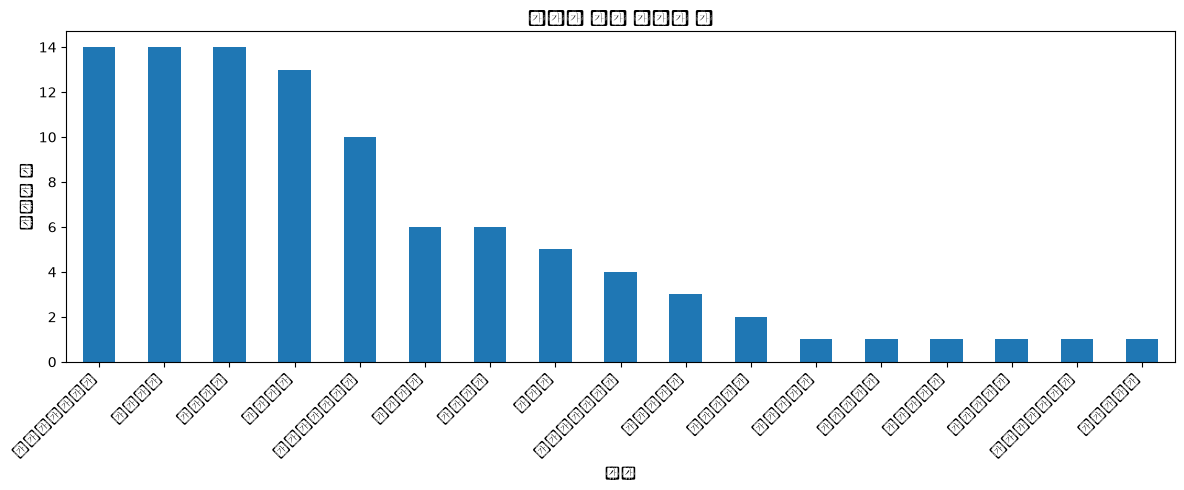

In [13]:
import matplotlib.pyplot as plt

station_count = (
    station_check["시도"]
    .value_counts()
    .sort_values(ascending=False)
)

station_count.plot(kind="bar", figsize=(12, 5))

plt.title("시도별 기상 관측소 수")
plt.xlabel("시도")
plt.ylabel("관측소 수")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [14]:
missing_dates = []

for (station_id, station_name), group in df.groupby(["지점", "지점명"]):
    observed_dates = pd.DatetimeIndex(group["일시"])

    # 해당 관측소의 첫 관측일부터 마지막 관측일까지 생성
    expected_dates = pd.date_range(
        start=observed_dates.min(),
        end=observed_dates.max(),
        freq="D"
    )

    # 실제 관측 날짜와 비교
    missing = expected_dates.difference(observed_dates)

    for date in missing:
        missing_dates.append({
            "지점": station_id,
            "지점명": station_name,
            "누락일자": date
        })

missing_df = pd.DataFrame(missing_dates)

print("관측 기간 내 누락 날짜 수:", len(missing_df))
display(missing_df.head(20))

관측 기간 내 누락 날짜 수: 130


,지점,지점명,누락일자
0,99,파주,2024-03-23
1,100,대관령,2025-10-31
2,100,대관령,2025-11-01
3,100,대관령,2025-11-02
4,100,대관령,2025-11-03
5,100,대관령,2025-11-04
6,101,춘천,2024-12-25
7,101,춘천,2025-06-06
8,101,춘천,2025-06-07
9,127,충주,2025-03-04


In [15]:
missing_count = (
    missing_df
    .groupby(["지점", "지점명"])
    .size()
    .reset_index(name="누락일수")
    .sort_values("누락일수", ascending=False)
)

print("누락 날짜가 발생한 관측소 수:", len(missing_count))
display(missing_count)

누락 날짜가 발생한 관측소 수: 34


,지점,지점명,누락일수
7,172,고창,31
24,268,진도군,11
22,263,의령군,9
14,217,정선군,8
21,261,해남,7
17,252,영광군,6
23,264,함양군,5
1,100,대관령,5
13,212,홍천,4
6,170,완도,4


In [16]:
# 최저기온 또는 최고기온이 비어 있는 행
missing_temp = df[
    df["최저기온(°C)"].isna() |
    df["최고기온(°C)"].isna()
]

print("기온 결측 행 수:", len(missing_temp))

display(
    missing_temp[
        ["지점", "지점명", "일시", "최저기온(°C)", "최고기온(°C)"]
    ]
)

기온 결측 행 수: 18


,지점,지점명,일시,최저기온(°C),최고기온(°C)
12565,101,춘천,2025-06-05,10.3,NaN
20661,108,서울,2022-08-08,NaN,28.4
50437,143,대구,2024-02-21,3.6,NaN
56239,155,창원,2025-01-10,-10.9,NaN
56240,155,창원,2025-01-11,NaN,4.5
59294,159,부산,2023-05-24,NaN,22.9
61451,162,통영,2024-04-21,NaN,16.6
69405,172,고창,2021-02-04,-4.3,NaN
86505,201,강화,2025-05-07,6.6,NaN
109278,239,세종,2022-09-29,15.1,NaN


In [17]:
# 필요한 컬럼만 선택
temperature_clean = df[
    ["지점", "지점명", "시도", "일시", "최저기온(°C)", "최고기온(°C)"]
].copy()

# 날짜 오름차순 정렬
temperature_clean = temperature_clean.sort_values(
    ["지점", "일시"]
).reset_index(drop=True)

# 데이터 확인
print("정제 데이터 크기:", temperature_clean.shape)
print("최저기온 결측:", temperature_clean["최저기온(°C)"].isna().sum())
print("최고기온 결측:", temperature_clean["최고기온(°C)"].isna().sum())

display(temperature_clean.head())

정제 데이터 크기: (175402, 6)
최저기온 결측: 10
최고기온 결측: 8


,지점,지점명,시도,일시,최저기온(°C),최고기온(°C)
0,90,속초,강원특별자치도,2021-01-01,-7.7,1.2
1,90,속초,강원특별자치도,2021-01-02,-6.3,1.5
2,90,속초,강원특별자치도,2021-01-03,-5.8,0.7
3,90,속초,강원특별자치도,2021-01-04,-4.2,3.2
4,90,속초,강원특별자치도,2021-01-05,-7.3,0.1


In [18]:
temperature_clean.to_csv(
    "기상_일별_최고최저기온_정제.csv",
    index=False,
    encoding="utf-8-sig"
)